In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path
from scipy import sparse

from google.colab import drive
drive.mount("/content/drive")

PROJECT_PATH = Path("/content/drive/MyDrive/Home Credit Default Risk")
PROCESSED_PATH = PROJECT_PATH / "data" / "processed"
MODEL_PATH = PROJECT_PATH / "models"

X_val = sparse.load_npz(PROCESSED_PATH / "X_val.npz")
y_val = pd.read_csv(
    PROCESSED_PATH / "y_val.csv"
).squeeze("columns")

print("Validation data:", X_val.shape)

Mounted at /content/drive
Validation data: (46127, 318)


In [2]:
log_reg = joblib.load(
    MODEL_PATH / "logistic_regression.joblib"
)

best_lgbm = joblib.load(
    MODEL_PATH / "lightgbm_tuned.joblib"
)

best_xgb = joblib.load(
    MODEL_PATH / "xgboost_tuned.joblib"
)

print("All models loaded successfully!")

All models loaded successfully!


In [3]:
model_probs = {
    "Logistic Regression": log_reg.predict_proba(X_val)[:, 1],
    "LightGBM": best_lgbm.predict_proba(X_val)[:, 1],
    "XGBoost": best_xgb.predict_proba(X_val)[:, 1]
}

print("Validation predictions generated!")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Validation predictions generated!


## 1. Probability Calibration

Probability calibration evaluates whether predicted default probabilities
correspond to observed repayment-difficulty rates.

A well-calibrated model assigning a 20% probability of default to a
group of borrowers should observe approximately 20% actual defaults
within that group.

Calibration curves and Brier scores are used to evaluate the probability
estimates of Logistic Regression, LightGBM, and XGBoost.

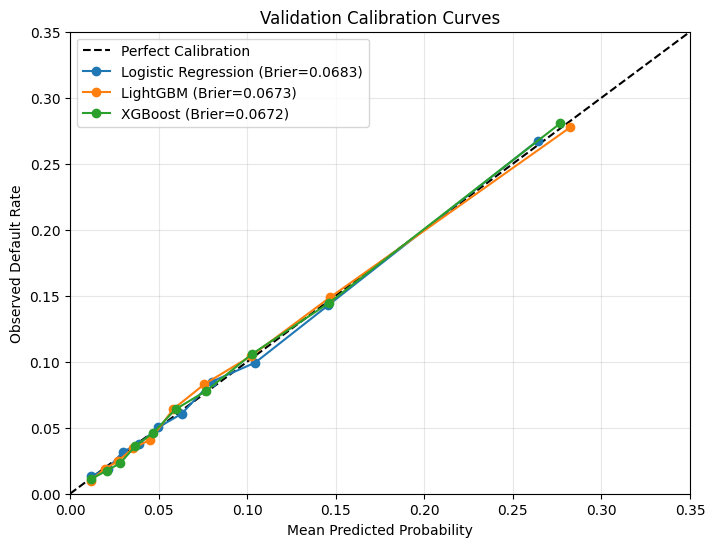

In [4]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

plt.figure(figsize=(8, 6))

plt.plot(
    [0, 0.35],
    [0, 0.35],
    linestyle="--",
    color="black",
    label="Perfect Calibration"
)

for name, probs in model_probs.items():

    fraction_positive, mean_predicted = calibration_curve(
        y_val,
        probs,
        n_bins=10,
        strategy="quantile"
    )

    brier = brier_score_loss(y_val, probs)

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=f"{name} (Brier={brier:.4f})"
    )

plt.xlim(0, 0.35)
plt.ylim(0, 0.35)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Default Rate")
plt.title("Validation Calibration Curves")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Calibration Results

Calibration curves were constructed using ten quantile-based bins
to evaluate the agreement between predicted default probabilities
and observed repayment-difficulty rates.

All three models demonstrated close alignment with the perfect
calibration reference line across the evaluated probability ranges.

XGBoost achieved the lowest Brier score (0.0672), followed by
LightGBM (0.0673) and Logistic Regression (0.0683).

Although LightGBM achieved a slightly higher ROC-AUC, XGBoost
achieved marginally better PR-AUC and Brier score.

Given the small performance differences and favorable calibration
results, additional probability calibration was not performed
at this stage.

## 2. Decile Analysis and Risk Ranking

Decile analysis evaluates how effectively the models rank borrowers
according to predicted repayment-difficulty risk.

Validation observations are sorted by predicted default probability
and divided into ten approximately equal-sized groups, with Decile 1
representing the highest predicted risk.

For each decile, we calculate:
- Average predicted default probability
- Observed default rate
- Lift relative to the overall default rate
- Number of observed defaults
- Cumulative percentage of defaults captured

This analysis helps assess the practical usefulness of the models
for identifying and prioritizing high-risk borrowers.

In [5]:
def decile_analysis(y_true, y_prob):

    df = pd.DataFrame({
        "Actual": np.asarray(y_true),
        "Predicted_Probability": np.asarray(y_prob)
    })

    # Sort borrowers from highest to lowest predicted risk
    df = df.sort_values(
        "Predicted_Probability",
        ascending=False
    ).reset_index(drop=True)

    # Assign approximately equal-sized deciles
    df["Decile"] = (
        np.floor(np.arange(len(df)) * 10 / len(df)).astype(int) + 1
    )

    overall_default_rate = df["Actual"].mean()
    total_defaults = df["Actual"].sum()

    results = df.groupby("Decile").agg(
        Borrowers=("Actual", "count"),
        Avg_Predicted_PD=("Predicted_Probability", "mean"),
        Actual_Default_Rate=("Actual", "mean"),
        Defaults=("Actual", "sum")
    )

    results["Lift"] = (
        results["Actual_Default_Rate"] / overall_default_rate
    )

    results["Cumulative_Default_Capture"] = (
        results["Defaults"].cumsum() / total_defaults
    )

    return results


lgbm_deciles = decile_analysis(
    y_val,
    model_probs["LightGBM"]
)

xgb_deciles = decile_analysis(
    y_val,
    model_probs["XGBoost"]
)

print("LightGBM Decile Analysis")
display(lgbm_deciles.round(4))

print("\nXGBoost Decile Analysis")
display(xgb_deciles.round(4))

LightGBM Decile Analysis


,Borrowers,Avg_Predicted_PD,Actual_Default_Rate,Defaults,Lift,Cumulative_Default_Capture
Decile,,,,,,
1,4613,0.2823,0.2775,1280,3.4369,0.3437
2,4613,0.1470,0.1489,687,1.8447,0.5282
3,4613,0.1021,0.1045,482,1.2942,0.6576
4,4612,0.0759,0.0828,382,1.0259,0.7602
5,4613,0.0583,0.0642,296,0.7948,0.8397
6,4613,0.0453,0.0410,189,0.5075,0.8904
7,4612,0.0356,0.0345,159,0.4270,0.9331
8,4613,0.0273,0.0249,115,0.3088,0.9640
9,4613,0.0199,0.0191,88,0.2363,0.9876



XGBoost Decile Analysis


,Borrowers,Avg_Predicted_PD,Actual_Default_Rate,Defaults,Lift,Cumulative_Default_Capture
Decile,,,,,,
1,4613,0.2767,0.2805,1294,3.4745,0.3475
2,4613,0.1465,0.1448,668,1.7937,0.5269
3,4613,0.1027,0.1058,488,1.3103,0.6579
4,4612,0.0770,0.0781,360,0.9668,0.7546
5,4613,0.0595,0.0639,295,0.7921,0.8338
6,4613,0.0468,0.0460,212,0.5692,0.8907
7,4612,0.0369,0.0362,167,0.4485,0.9356
8,4613,0.0284,0.0232,107,0.2873,0.9643
9,4613,0.0209,0.0176,81,0.2175,0.9860


### Decile Analysis Results

Decile analysis was conducted on the validation dataset to evaluate
how effectively LightGBM and XGBoost rank borrowers by predicted
repayment-difficulty risk.

Both models demonstrated strong risk separation. XGBoost's highest-risk
decile had an observed default rate of 28.05%, approximately 3.47 times
the overall default rate of 8.07%.

The highest-risk 10% of borrowers accounted for 34.75% of observed
defaults under XGBoost, compared with 34.37% under LightGBM.

When expanding to the highest-risk 20%, LightGBM captured 52.82%
of defaults, compared with 52.69% for XGBoost.

These small differences suggest that both models provide comparable
risk-ranking performance. The close agreement between predicted
and observed default rates within deciles also supports their
reasonable aggregate calibration.

XGBoost was provisionally selected for subsequent interpretability
and decision-threshold analysis due to its marginally better PR-AUC,
Brier score, and top-decile default capture.

## 3. Model Interpretability and Feature Importance

Model interpretability is essential in credit risk modeling because
predictions may influence financial decisions.

This section examines which features contribute most strongly to
XGBoost's predictions.

First, built-in feature importance is used to identify influential
variables. Next, SHAP analysis will be used to investigate how
individual features contribute to predicted repayment-difficulty risk.

In [6]:
feature_names = pd.read_csv(
    PROCESSED_PATH / "feature_names.csv"
)["feature"].tolist()

print("Number of features:", len(feature_names))
print("Model features:", best_xgb.n_features_in_)

Number of features: 318
Model features: 318


In [7]:
# Retrieve XGBoost feature importance using gain
booster = best_xgb.get_booster()

gain_scores = booster.get_score(importance_type="gain")

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Gain": [
        gain_scores.get(f"f{i}", 0.0)
        for i in range(len(feature_names))
    ]
})

importance_df = importance_df.sort_values(
    "Gain",
    ascending=False
).reset_index(drop=True)

display(importance_df.head(20))

,Feature,Gain
0,num__EXT_SOURCE_2,114.002991
1,num__EXT_SOURCE_3,112.711998
2,cat__NAME_EDUCATION_TYPE_Higher education,82.901131
3,num__FLAG_DOCUMENT_3,66.670242
4,num__missingindicator_AMT_REQ_CREDIT_BUREAU_HOUR,51.134193
5,num__missingindicator_AMT_REQ_CREDIT_BUREAU_DAY,50.695824
6,cat__CODE_GENDER_F,44.643169
7,cat__NAME_INCOME_TYPE_Working,44.099659
8,cat__CODE_GENDER_M,43.231167
9,num__EXT_SOURCE_1,43.194637


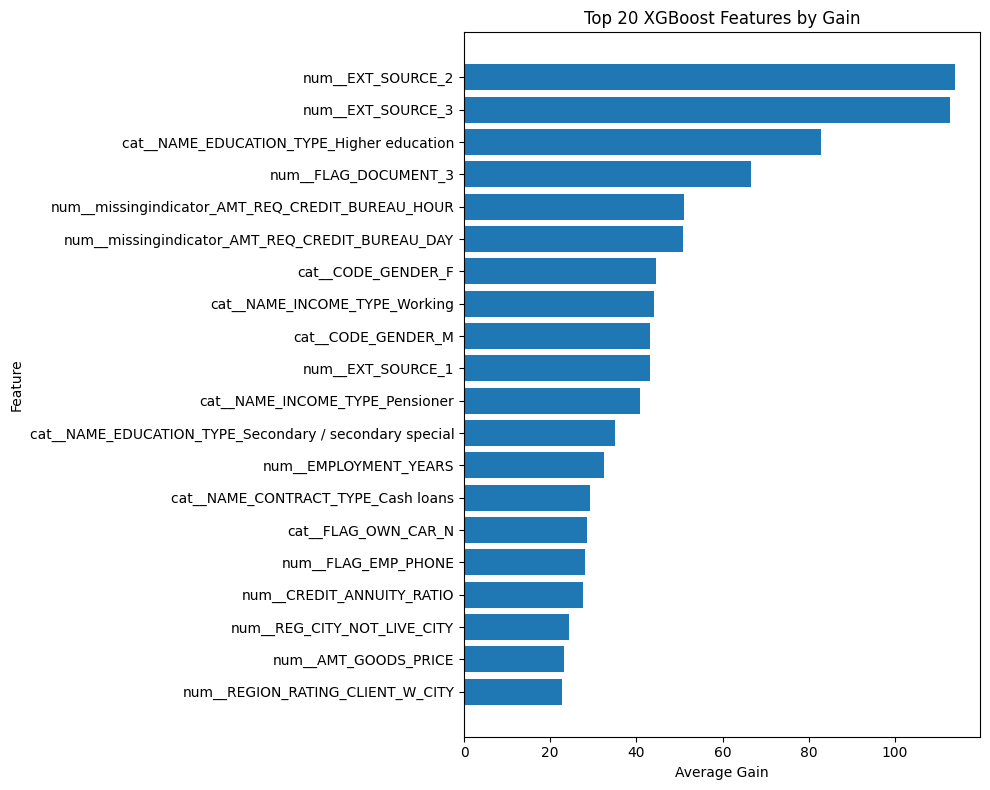

In [8]:
top_features = importance_df.head(20).sort_values("Gain")

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Gain"]
)

plt.xlabel("Average Gain")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Features by Gain")

plt.tight_layout()
plt.show()

### XGBoost Feature Importance Results

XGBoost feature importance was evaluated using average gain,
which measures the improvement in the model's splitting objective
associated with a feature.

EXT_SOURCE_2 and EXT_SOURCE_3 were the most influential predictors,
consistent with their strong associations with repayment difficulty
observed during exploratory data analysis.

Education, employment history, application documentation, and
credit bureau missingness indicators also contributed to the model.

The importance of missingness indicators suggests that the
availability of applicant information contains predictive value.

Gender-related variables were also prominent, highlighting the
need to consider fairness and the appropriateness of predictors
in financial decision-making.

Because gain-based feature importance does not indicate the
direction of a feature's influence, SHAP analysis will be used
to provide more detailed explanations of model predictions.

## 4. SHAP Model Explainability

SHAP (SHapley Additive exPlanations) is used to interpret
the XGBoost model by estimating how individual features
contribute to its predictions.

A sample of 500 validation observations is used to reduce
computational requirements.

SHAP values will be examined to identify influential
features and understand whether they increase or decrease
the model's predicted repayment-difficulty risk.

In [10]:
import shap

# Random sample of 500 validation observations
rng = np.random.default_rng(42)

sample_idx = rng.choice(
    X_val.shape[0],
    size=500,
    replace=False
)

X_shap = X_val[sample_idx].toarray()

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (500, 318)


In [11]:
explainer = shap.TreeExplainer(best_xgb)

shap_values = explainer(X_shap)

print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (500, 318)


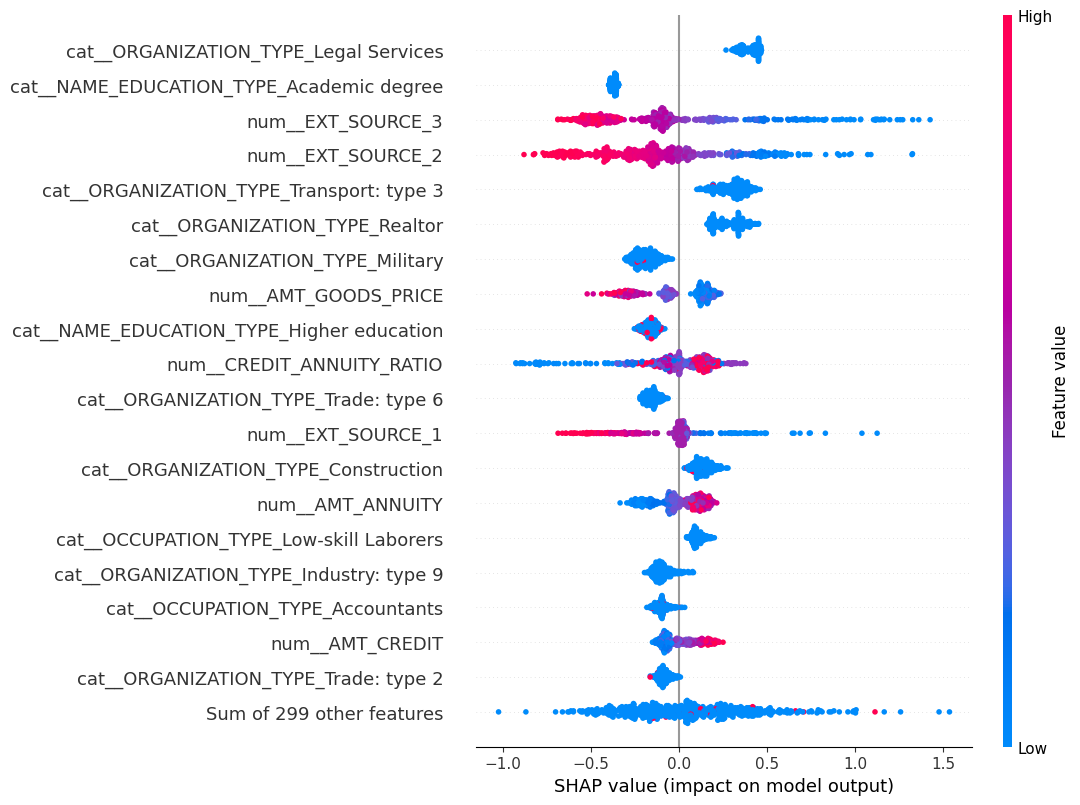

In [12]:
# Attach feature names to the SHAP explanations
shap_values.feature_names = feature_names

# Generate SHAP summary plot
shap.plots.beeswarm(
    shap_values,
    max_display=20
)

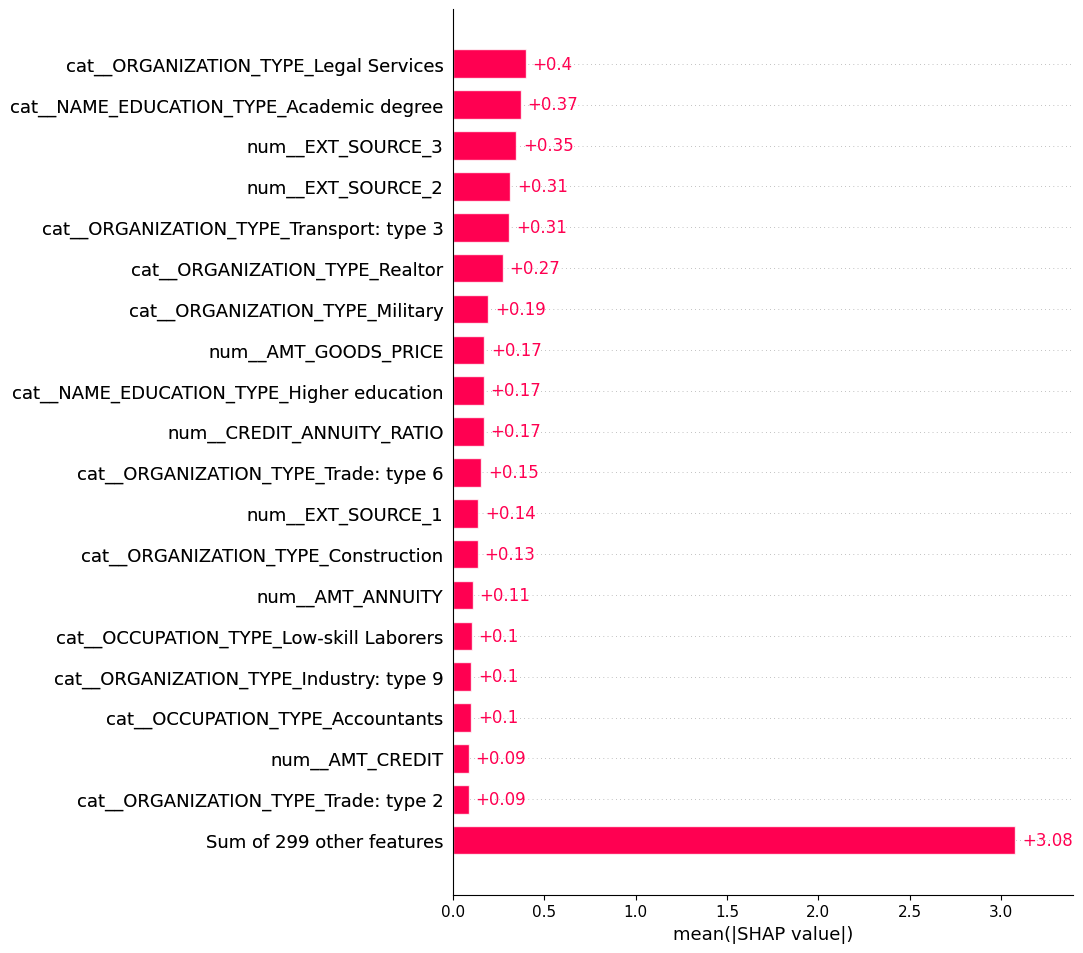

In [13]:
shap.plots.bar(
    shap_values,
    max_display=20
)

In [14]:
print("Number of feature names:", len(feature_names))
print("Number of model features:", best_xgb.n_features_in_)
print("Number of SHAP columns:", shap_values.values.shape[1])

print("\nFirst 10 feature names:")
print(feature_names[:10])

print("\nFirst 10 model feature names:")
print(best_xgb.get_booster().feature_names[:10]
      if best_xgb.get_booster().feature_names is not None
      else "Model uses positional feature names")

Number of feature names: 318
Number of model features: 318
Number of SHAP columns: 318

First 10 feature names:
['num__CNT_CHILDREN', 'num__AMT_INCOME_TOTAL', 'num__AMT_CREDIT', 'num__AMT_ANNUITY', 'num__AMT_GOODS_PRICE', 'num__REGION_POPULATION_RELATIVE', 'num__DAYS_REGISTRATION', 'num__DAYS_ID_PUBLISH', 'num__OWN_CAR_AGE', 'num__FLAG_MOBIL']

First 10 model feature names:
Model uses positional feature names


### SHAP Summary Analysis

SHAP analysis was performed on a random sample of 500 validation
observations to investigate the direction and magnitude of feature
contributions to XGBoost predictions.

EXT_SOURCE_2, EXT_SOURCE_3, and EXT_SOURCE_1 showed consistent
patterns: higher external scores generally contributed toward
lower predicted repayment-difficulty risk.

Financial variables such as CREDIT_ANNUITY_RATIO and AMT_ANNUITY
also contributed to predictions.

Several organization-type indicators appeared prominently in
the SHAP ranking. Because these variables are one-hot encoded
and may represent relatively rare categories, their contributions
require careful interpretation.

SHAP values describe how features contribute to model predictions
rather than establishing causal relationships.

In [15]:
# Predictions for our SHAP sample
sample_probs = best_xgb.predict_proba(X_shap)[:, 1]

# Select highest-risk borrower in the sample
high_risk_idx = np.argmax(sample_probs)

print("Borrower index:", high_risk_idx)
print("Predicted default probability:", round(sample_probs[high_risk_idx], 4))

Borrower index: 181
Predicted default probability: 0.473


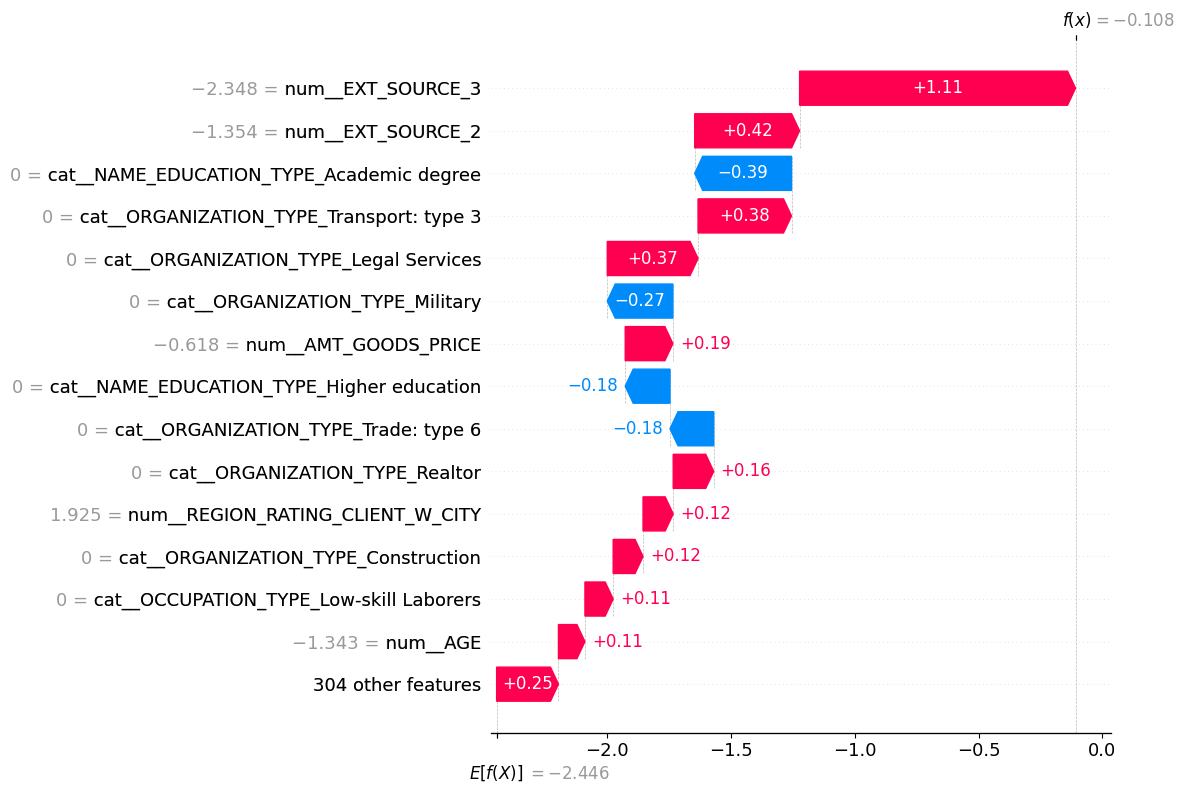

In [16]:
shap.plots.waterfall(
    shap_values[high_risk_idx],
    max_display=15
)

In [17]:
from scipy.special import expit

shap_raw_prediction = (
    shap_values.base_values[high_risk_idx]
    + shap_values.values[high_risk_idx].sum()
)

shap_probability = expit(shap_raw_prediction)

print("XGBoost probability:", sample_probs[high_risk_idx])
print("SHAP reconstructed probability:", shap_probability)

XGBoost probability: 0.47295308
SHAP reconstructed probability: 0.47295287


### Individual Prediction Explanation

A SHAP waterfall plot was generated for the highest-risk borrower
within a random sample of 500 validation observations.

The selected borrower received a predicted repayment-difficulty
probability of approximately 47.30%, substantially above the
overall validation event rate of 8.07%.

The largest positive SHAP contributions came from EXT_SOURCE_3
and EXT_SOURCE_2, indicating that these variables were major
drivers of the borrower's elevated predicted risk.

Other features, including education and organization-type
indicators, contributed in both directions.

The reconstructed probability from SHAP values (0.47295287)
closely matched the original XGBoost prediction (0.47295308),
confirming numerical consistency.

SHAP explanations describe contributions to model predictions,
not causal effects of borrower characteristics.

## 5. Decision-Threshold Optimization

The XGBoost model produces estimated probabilities of repayment
difficulty rather than direct classification decisions.

This section evaluates how different classification thresholds
affect precision, recall, F1-score, and the number of false
positives and false negatives.

Because the target variable is imbalanced, the default 0.50
threshold may not provide an appropriate balance between
identifying high-risk borrowers and avoiding unnecessary flags.

Thresholds are evaluated using the validation dataset.

In [18]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Use our saved XGBoost validation predictions
y_prob = model_probs["XGBoost"]

thresholds = [
    0.05, 0.075, 0.10, 0.125,
    0.15, 0.175, 0.20, 0.25,
    0.30, 0.40, 0.50
]

threshold_results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Flagged": int(y_pred.sum()),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "False Positives": int(fp),
        "False Negatives": int(fn)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Flagged,Precision,Recall,F1,False Positives,False Negatives
0,0.050,24053,0.1311,0.8467,0.2270,20900,571
1,0.075,16575,0.1613,0.7180,0.2635,13901,1050
2,0.100,11804,0.1901,0.6026,0.2890,9560,1480
3,0.125,8703,0.2192,0.5124,0.3071,6795,1816
4,0.150,6516,0.2452,0.4291,0.3121,4918,2126
5,0.175,4925,0.2763,0.3655,0.3147,3564,2363
6,0.200,3783,0.2987,0.3034,0.3011,2653,2594
7,0.250,2296,0.3445,0.2124,0.2628,1505,2933
8,0.300,1376,0.4150,0.1533,0.2239,805,3153
9,0.400,493,0.4706,0.0623,0.1100,261,3492


## 6. Cost-Sensitive Threshold Optimization

Classification errors may have different financial consequences
in credit risk applications.

A false negative represents a borrower who experiences repayment
difficulty but is not flagged, while a false positive represents
a borrower who is flagged despite not experiencing repayment difficulty.

To demonstrate cost-sensitive decision-making, hypothetical costs
of $5,000 per false negative and $500 per false positive are used.

These values are illustrative and do not represent actual lending
losses or operational costs.

The total classification cost is calculated across candidate
thresholds to identify the threshold that minimizes cost under
the assumed scenario.

In [20]:
# Hypothetical costs
COST_FP = 500
COST_FN = 5000

cost_df = threshold_df.copy()

cost_df["FP Cost"] = (
    cost_df["False Positives"] * COST_FP
)

cost_df["FN Cost"] = (
    cost_df["False Negatives"] * COST_FN
)

cost_df["Total Cost"] = (
    cost_df["FP Cost"] + cost_df["FN Cost"]
)

display(
    cost_df[
        ["Threshold", "False Positives",
         "False Negatives", "Total Cost"]
    ].sort_values("Total Cost")
)

best_cost_threshold = cost_df.loc[
    cost_df["Total Cost"].idxmin()
]

print(
    f"Lowest-cost threshold among those tested: "
    f"{best_cost_threshold['Threshold']:.3f}"
)

print(
    f"Estimated total cost: "
    f"${best_cost_threshold['Total Cost']:,.0f}"
)

,Threshold,False Positives,False Negatives,Total Cost
2,0.100,9560,1480,12180000
1,0.075,13901,1050,12200500
3,0.125,6795,1816,12477500
4,0.150,4918,2126,13089000
0,0.050,20900,571,13305000
5,0.175,3564,2363,13597000
6,0.200,2653,2594,14296500
7,0.250,1505,2933,15417500
8,0.300,805,3153,16167500
9,0.400,261,3492,17590500


Lowest-cost threshold among those tested: 0.100
Estimated total cost: $12,180,000


### Fine-Grained Cost Optimization

The initial threshold sweep identified 0.10 as the lowest-cost
threshold among the evaluated candidates.

A finer search between 0.07 and 0.12 is performed to identify
a more precise cost-minimizing threshold under the assumed
false-positive and false-negative costs.

The resulting threshold is specific to the hypothetical cost
scenario and validation dataset.

In [21]:
fine_thresholds = np.round(
    np.arange(0.07, 0.1201, 0.001),
    3
)

fine_results = []

for threshold in fine_thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    total_cost = fp * COST_FP + fn * COST_FN

    fine_results.append({
        "Threshold": threshold,
        "False Positives": fp,
        "False Negatives": fn,
        "Total Cost": total_cost
    })

fine_cost_df = pd.DataFrame(fine_results)

display(
    fine_cost_df.sort_values("Total Cost").head(10)
)

,Threshold,False Positives,False Negatives,Total Cost
16,0.086,11698,1239,12044000
14,0.084,12044,1207,12057000
21,0.091,10935,1318,12057500
15,0.085,11879,1224,12059500
19,0.089,11254,1287,12062000
17,0.087,11545,1258,12062500
18,0.088,11405,1272,12062500
13,0.083,12241,1189,12065500
22,0.092,10794,1335,12072000
20,0.090,11099,1305,12074500


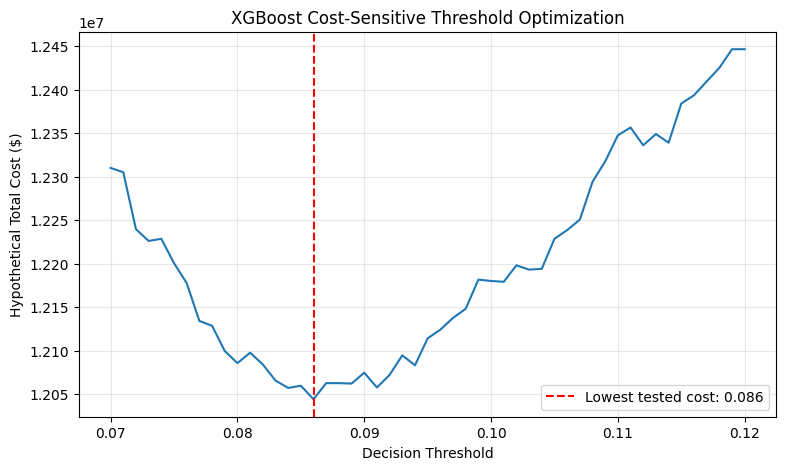

Best threshold: 0.086
Minimum cost: $12,044,000


In [22]:
plt.figure(figsize=(9, 5))

plt.plot(
    fine_cost_df["Threshold"],
    fine_cost_df["Total Cost"]
)

best_row = fine_cost_df.loc[
    fine_cost_df["Total Cost"].idxmin()
]

plt.axvline(
    best_row["Threshold"],
    linestyle="--",
    color="red",
    label=f"Lowest tested cost: {best_row['Threshold']:.3f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Hypothetical Total Cost ($)")
plt.title("XGBoost Cost-Sensitive Threshold Optimization")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Best threshold:", best_row["Threshold"])
print(f"Minimum cost: ${best_row['Total Cost']:,.0f}")

### Cost-Sensitive Threshold Optimization Results

A fine-grained threshold search was conducted between 0.07 and
0.12 using increments of 0.001.

Under the hypothetical cost assumptions of $500 per false
positive and $5,000 per false negative, the lowest observed
validation cost occurred at a threshold of 0.086.

At this threshold, the model produced 11,698 false positives
and 1,239 false negatives, resulting in a total hypothetical
classification cost of $12,044,000.

The selected threshold achieved approximately 66.73% recall
and 17.52% precision.

Compared with the default 0.50 threshold, the optimized
threshold reduced simulated classification costs by
approximately 33.9%.

The empirical optimum was close to the theoretical
cost-based threshold of 0.0909.

These results demonstrate the importance of aligning
classification decisions with explicit business costs.
The estimated savings are hypothetical and do not represent
actual financial losses avoided.

In [23]:
import json

final_config = {
    "model": "XGBoost",
    "configuration": "Shallow Trees",
    "decision_threshold": 0.086,
    "false_positive_cost": 500,
    "false_negative_cost": 5000,
    "threshold_selection": "Validation cost minimization",
    "random_state": 42
}

with open(MODEL_PATH / "final_model_config.json", "w") as f:
    json.dump(final_config, f, indent=4)

print("Final model configuration saved successfully!")

Final model configuration saved successfully!
